# Emulator vs. simulator: soybean at new sites

This notebook applies the exported emulators (`cropemu`) to sites and seasons **that were not in
the training data** and compares them with the crop models they emulate, run on exactly the same
inputs:

1. choose sites (coordinates only) and draw seasons (sowing dates, cultivars) with the same design used in training;
2. run the official **DSSAT CROPGRO-Soybean** and **AquaCrop 7.3** executables (`cropemu-bench`);
3. predict the same seasons with the emulators through the public API of the library
   (`cropemu.load(...).predict(weather, lat, soil, sowing, cultivar)`), as an end user would;
4. compare: errors per output, scatter plots, acceptance levels of the card and run time.

Requirements: `cropemu` (`pip install "cropemu[soil]"`, the emulators ship inside it), `cropemu-bench`, the DSSAT and AquaCrop executables
(`CROPEMU_DSSAT_EXE`, `CROPEMU_DSSAT_HOME`, `CROPEMU_AQUACROP_EXE`, `CROPEMU_AQUACROP_DATA`)
and internet access for NASA POWER and SoilGrids (cached in `CROPEMU_CACHE`).

In [1]:
import os, time, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cropemu
from cropemu.soil import soilgrids
from cropemu.weather import fetch, fill_gaps
from cropemu_bench import pipeline, pipeline_aquacrop
from cropemu_bench.dataset import build
from cropemu_bench.design.seasons import SeasonDesign

ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
WORK = Path(os.environ.get("CROPEMU_NOTEBOOK_WORK", tempfile.mkdtemp(prefix="cropemu_nb_")))
SEASONS_PER_SITE = int(os.environ.get("CROPEMU_NOTEBOOK_SEASONS", 25))
print("cropemu", cropemu.__version__, cropemu.available(), WORK)

cropemu 0.1.0 ['aquacrop-soybean-v1', 'dssat-soybean-v1'] /var/folders/50/s8hjm0h134j6vnljh7hmbhqc0000gn/T/cropemu_nb_31p_7c6v


## 1. Sites and seasons

Producing regions in South and North America and Asia. The training points are a global sample
on a 0.5° grid; these coordinates are new. The seasons follow the training design (sowing within
±30 days of the GGCMI date, cultivar sampled around the maturity group of the latitude, 20 % without
water stress), **without** the climate perturbations (warming, rain factor, CO₂), which the library
does not apply to observed weather.

In [2]:
sites = pd.DataFrame([
    ("Londrina-PR",     -23.19, -51.18),
    ("Rio Verde-GO",    -17.80, -50.92),
    ("Sorriso-MT",      -12.55, -55.71),
    ("Passo Fundo-RS",  -28.26, -52.41),
    ("Pergamino-AR",    -33.89, -60.57),
    ("Ames-IA",          42.03, -93.62),
    ("Harbin-CN",        46.20, 126.50),
], columns=["id", "lat", "lon"])   # farmland near each town (SoilGrids has no soil in urban pixels)
sites["block"], sites["koppen"], sites["kind"] = "new", "", "new_site"
design = SeasonDesign(seasons_per_point=SEASONS_PER_SITE, perturbed_share=0.0, seed=7)
SITE_ORDER = list(sites["id"])
sites

,id,lat,lon,block,koppen,kind
0,Londrina-PR,-23.19,-51.18,new,,new_site
1,Rio Verde-GO,-17.80,-50.92,new,,new_site
2,Sorriso-MT,-12.55,-55.71,new,,new_site
3,Passo Fundo-RS,-28.26,-52.41,new,,new_site
4,Pergamino-AR,-33.89,-60.57,new,,new_site
5,Ames-IA,42.03,-93.62,new,,new_site
6,Harbin-CN,46.20,126.50,new,,new_site


## 2. Simulations (official executables)

In [3]:
t0 = time.time()
dssat_dir = pipeline.generate(sites, WORK / "dssat", design, points_per_batch=len(sites), progress=False)
t_dssat = time.time() - t0
t0 = time.time()
aq_dir = pipeline_aquacrop.generate(dssat_dir, WORK / "aquacrop", points_per_batch=len(sites), progress=False)
t_aq = time.time() - t0

# truth: the same targets the emulators were trained on (dates as days after sowing, ...)
truth = {}
for name, folder in (("dssat", dssat_dir), ("aquacrop", aq_dir)):
    X, Y, info = build(folder, derived=True)
    truth[name] = (X, Y, info)
    print(f"{name}: {len(Y)} seasons, {Y.shape[1]} outputs")
print(f"simulation time: DSSAT {t_dssat:.0f} s, AquaCrop {t_aq:.0f} s")

weather: 7 ok, 0 errors in 0s
soil: 7 points in 0s


dssat: 175 seasons, 41 outputs


aquacrop: 175 seasons, 43 outputs
simulation time: DSSAT 7 s, AquaCrop 7 s


## 3. Emulator predictions through the library

Only what an end user has: coordinates, the NASA POWER weather, the SoilGrids profile
(the water retention is computed by the method recorded in the card), the sowing date and the
cultivar parameters.

In [4]:
emus = {"dssat": cropemu.load("dssat-soybean-v1"), "aquacrop": cropemu.load("aquacrop-soybean-v1")}   # shipped with the package
for e in emus.values():
    print(e, "| soil:", e.card.get("hydraulics"))

def predict_all(emu, folder):
    design = pd.read_parquet(Path(folder) / "design.parquet")
    pts = pd.read_parquet(Path(folder) / "points.parquet").set_index("id")
    preds, inputs = [], []
    for pid, seasons in design.groupby("point"):
        p = pts.loc[pid]
        weather = fill_gaps(fetch(p["lat"], p["lon"], pipeline.WEATHER_START, pipeline.WEATHER_END))
        soil = soilgrids.fetch(p["lat"], p["lon"])
        for r in seasons.to_dict("records"):
            res = emu.predict(weather, lat=p["lat"], elev=p["elev"], soil=soil, sowing=r["sowing"],
                              cultivar={k: r[k] for k in emu.cultivar_}, irrigated=not r["water"])
            preds.append(res.outputs.assign(sample=r["sample"]))
            inputs.append(res.inputs.assign(sample=r["sample"],
                                            out_of_domain=len(res.out_of_domain.iloc[0]),
                                            rare=len(res.rare_inputs.iloc[0]),
                                            rare_names=",".join(res.rare_inputs.iloc[0]), point=pid))
    return pd.concat(preds).set_index("sample"), pd.concat(inputs).set_index("sample")

pred, used = {}, {}
for name in emus:
    t0 = time.time()
    pred[name], used[name] = predict_all(emus[name], dssat_dir if name == "dssat" else aq_dir)
    print(f"{name}: {len(pred[name])} seasons in {time.time() - t0:.1f} s (including weather/soil reads)")

Emulator('dssat-soybean-v1': DSSAT 4.8 CROPGRO-Soybean (official executable), soybean; 79 inputs, 39 outputs) | soil: hybrid
Emulator('aquacrop-soybean-v1': AquaCrop 7.3 (official executable), soybean; 82 inputs, 44 outputs) | soil: hybrid


dssat: 175 seasons in 3.7 s (including weather/soil reads)


aquacrop: 175 seasons in 3.0 s (including weather/soil reads)


The library builds its inputs with the same code as the training data
(`cropemu.features.season_inputs`). Check that they agree on these seasons:

In [5]:
for name in emus:
    X = truth[name][0]
    cols = emus[name].inputs_
    diff = (used[name].loc[X.index, cols] - X[cols]).abs().max()
    print(name, "max |library - training pipeline| input difference:", f"{diff.max():.2g}", f"({diff.idxmax()})")
    print("  seasons with inputs outside the training domain:", int((used[name]["out_of_domain"] > 0).sum()),
          "| with rare inputs:", int((used[name]["rare"] > 0).sum()))

dssat max |library - training pipeline| input difference: 0 (lat)
  seasons with inputs outside the training domain: 0 | with rare inputs: 39
aquacrop max |library - training pipeline| input difference: 0 (lat)
  seasons with inputs outside the training domain: 0 | with rare inputs: 49


Which inputs are rare (outside the 0.5-99.5 % range of training), by site. Cultivar parameters
near the edge of the sampled range and very deep soils are the usual reasons; the season is
still inside the domain.

In [6]:
for name in emus:
    u = used[name]
    r = u[u["rare"] > 0].assign(input=lambda t: t["rare_names"].str.split(",")).explode("input")
    print(name); display(pd.crosstab(r["point"], r["input"]).reindex(SITE_ORDER).fillna(0).astype(int))

dssat


input,EM-FL,LFMAX,SD-PM,SDPDV,SFDUR,SLAVR,paw_mm,rain_60_90,rain_90_130,sowing_cos,sowing_sin,vpd_60_90
point,,,,,,,,,,,,
Londrina-PR,0,0,0,0,0,1,0,0,0,0,1,0
Rio Verde-GO,0,0,0,1,0,0,0,0,0,0,0,0
Sorriso-MT,1,0,0,0,0,0,0,1,1,0,1,1
Passo Fundo-RS,0,0,0,0,1,0,0,0,0,0,0,0
Pergamino-AR,0,0,0,0,0,0,25,0,0,1,0,0
Ames-IA,0,1,0,0,0,1,0,0,0,0,0,0
Harbin-CN,1,1,1,0,0,0,0,0,0,0,0,0


aquacrop


input,cdc_gdd,cgc_gdd,cycle_factor,hio,kctr,p_exp_lower,p_exp_upper,p_sto,paw_mm,rain_60_90,rain_90_130,sowing_cos,sowing_sin,td_flowering,td_maturity,td_senescence,vpd_60_90,wp,zmax
point,,,,,,,,,,,,,,,,,,,
Londrina-PR,0,0,1,1,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0
Rio Verde-GO,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,1
Sorriso-MT,1,0,0,1,0,0,0,0,0,1,1,0,1,0,0,0,1,0,0
Passo Fundo-RS,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
Pergamino-AR,0,0,0,1,0,0,0,1,25,0,0,1,0,0,0,0,0,0,0
Ames-IA,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
Harbin-CN,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,2


## 4. Comparison

In [7]:
def metrics(Y, P, levels):
    rows = []
    for c in P.columns:
        if c not in Y:
            continue
        y, p = Y[c], P.loc[Y.index, c]
        ok = y.notna() & p.notna()
        if ok.sum() < 5:
            continue
        e = p[ok] - y[ok]
        rows.append({"output": c, "n": int(ok.sum()), "mean_sim": y[ok].mean(), "bias": e.mean(),
                     "rmse": np.sqrt((e ** 2).mean()), "r2": 1 - (e ** 2).sum() / ((y[ok] - y[ok].mean()) ** 2).sum(),
                     "card_rmse": levels.get(c, {}).get("rmse", np.nan),
                     "card_level": levels.get(c, {}).get("level", "")})
    return pd.DataFrame(rows).set_index("output")

tables = {}
for name in emus:
    acc = emus[name].card.get("acceptance", {})
    tables[name] = metrics(truth[name][1], pred[name], acc)

KEY = {"dssat": ["EDAT_dap", "ADAT_dap", "MDAT_dap", "HWAM", "CWAM", "LAIX", "ETCM", "PRCM", "YPEM"],
       "aquacrop": ["EMR_dap", "FLO_dap", "MAT_dap", "Y(dry)", "BioMass", "HI", "ET_crop", "Rain_crop", "WPet"]}
for name in emus:
    keys = [k for k in KEY[name] if k in tables[name].index] or list(tables[name].index[:10])
    print(name); display(tables[name].loc[keys].round(3))

dssat


,n,mean_sim,bias,rmse,r2,card_rmse,card_level
output,,,,,,,
EDAT_dap,175,9.154,0.013,1.057,0.983,3.553,recommended
ADAT_dap,175,48.434,-0.144,1.107,0.995,3.199,recommended
MDAT_dap,171,122.485,-0.218,1.941,0.990,3.287,recommended
HWAM,175,4076.046,13.438,329.839,0.951,453.751,caution
CWAM,175,7502.760,19.511,476.770,0.973,715.241,caution
LAIX,175,4.527,0.018,0.433,0.943,0.561,caution
ETCM,140,579.036,2.431,18.638,0.979,32.131,caution
PRCM,140,790.814,-9.542,47.091,0.982,54.293,caution
YPEM,140,7.345,0.027,0.656,0.904,0.946,caution


aquacrop


,n,mean_sim,bias,rmse,r2,card_rmse,card_level
output,,,,,,,
EMR_dap,167,15.922,0.112,0.932,0.985,1.074,recommended
FLO_dap,167,64.784,0.133,0.856,0.997,1.019,recommended
MAT_dap,157,112.338,0.003,1.383,0.998,4.356,recommended
Y(dry),175,2.553,-0.025,0.336,0.919,0.581,caution
BioMass,175,6.797,-0.039,0.897,0.917,1.452,caution
HI,175,37.133,-1.089,4.962,0.594,6.766,not recommended
ET_crop,175,424.705,5.998,27.524,0.920,52.450,caution
Rain_crop,175,550.718,-6.355,43.943,0.961,93.739,caution
WPet,175,0.595,-0.024,0.073,0.899,0.129,caution


`card_rmse` is the out-of-fold error of the spatial block validation recorded in the card;
the error at the new sites should be of the same order. Outputs marked *not recommended* in the
card are expected to do poorly.

## 5. Figures

In [8]:
# figure style: fixed categorical order per site (colour + marker), recessive axes
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
LEVEL_COLOR = {"recommended": "#0ca30c", "caution": "#fab219", "not recommended": "#d03b3b"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "0.9", "grid.linewidth": 0.6, "axes.edgecolor": "0.6",
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "legend.frameon": False, "figure.dpi": 110})
SITE_ORDER = list(sites["id"])
STYLE = {s: dict(color=SERIES[i], marker=MARKERS[i]) for i, s in enumerate(SITE_ORDER)}
UNITS = {"HWAM": "kg/ha", "CWAM": "kg/ha", "Y(dry)": "t/ha", "BioMass": "t/ha", "ETCM": "mm", "ET_crop": "mm",
         "LAIX": "m²/m²", "HI": "%", "CC_max": "%"}
LABEL = {"dssat": "DSSAT CROPGRO-Soybean", "aquacrop": "AquaCrop 7.3"}

def site_legend(fig, n=len(SITE_ORDER)):
    h = [plt.Line2D([], [], ls="", markersize=6, **STYLE[s]) for s in SITE_ORDER[:n]]
    fig.legend(h, SITE_ORDER[:n], loc="lower center", ncol=min(n, 7), bbox_to_anchor=(0.5, -0.02))

### 5.1 Sites

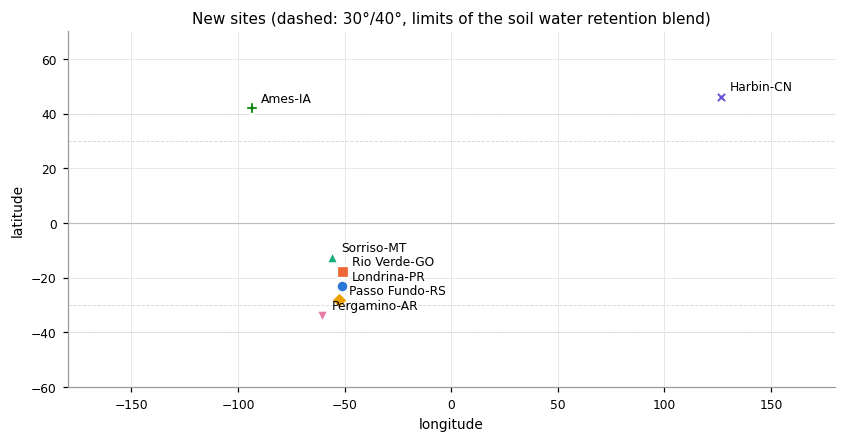

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
pts_used = pd.read_parquet(dssat_dir / "points.parquet")
for s in SITE_ORDER:
    r = sites.set_index("id").loc[s]
    ax.scatter(r["lon"], r["lat"], s=60, edgecolor="white", linewidth=1.5, zorder=3, **STYLE[s])
    ax.annotate(s, (r["lon"], r["lat"]), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.axhline(0, color="0.75", lw=0.8); [ax.axhline(v, color="0.85", lw=0.6, ls="--") for v in (-30, -40, 30, 40)]
ax.set(xlim=(-180, 180), ylim=(-60, 70), xlabel="longitude", ylabel="latitude",
       title="New sites (dashed: 30°/40°, limits of the soil water retention blend)")
plt.show()

### 5.2 Emulator vs simulator, season by season

Each point is one season (site, year, sowing date, cultivar). The grey line is 1:1; the box gives
the error at the new sites and, in brackets, the error of the block validation of the card.

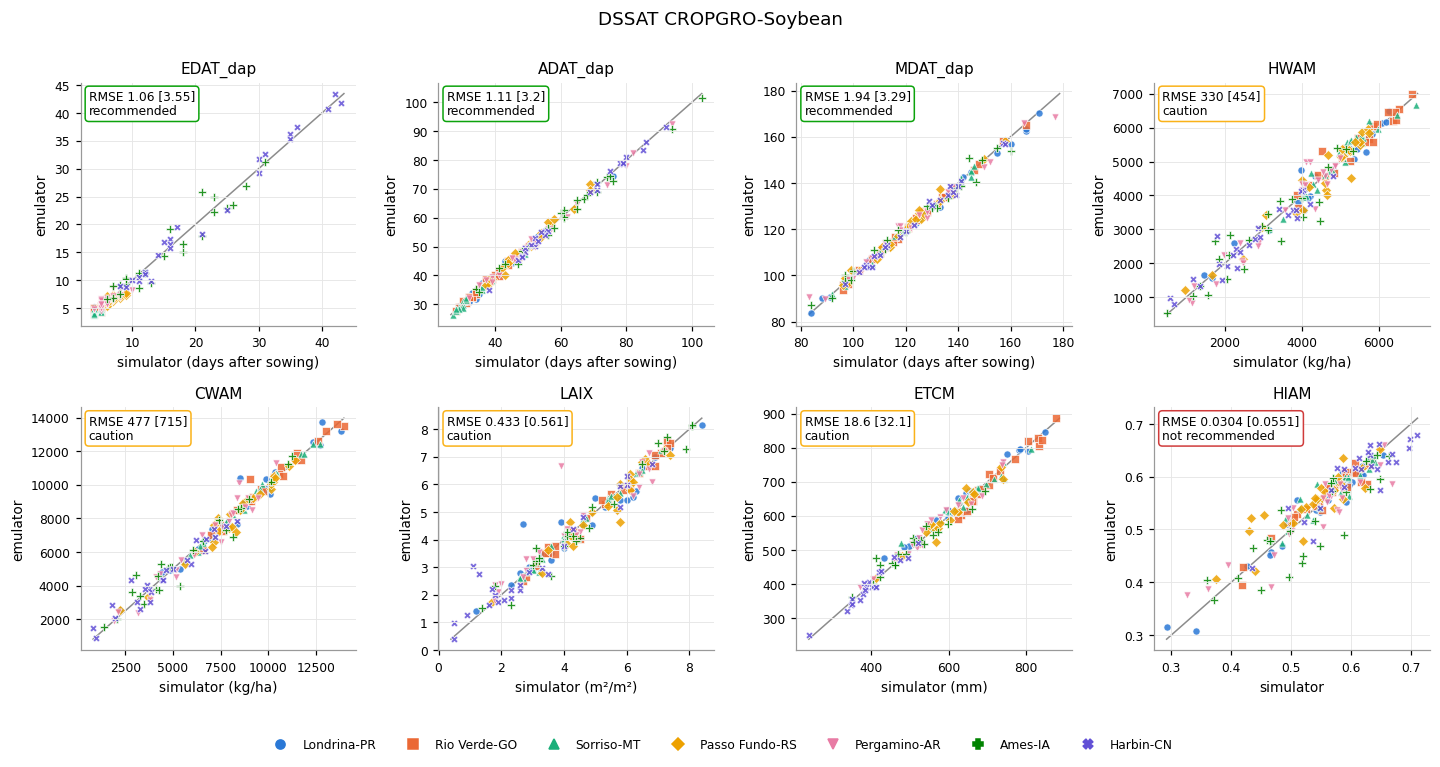

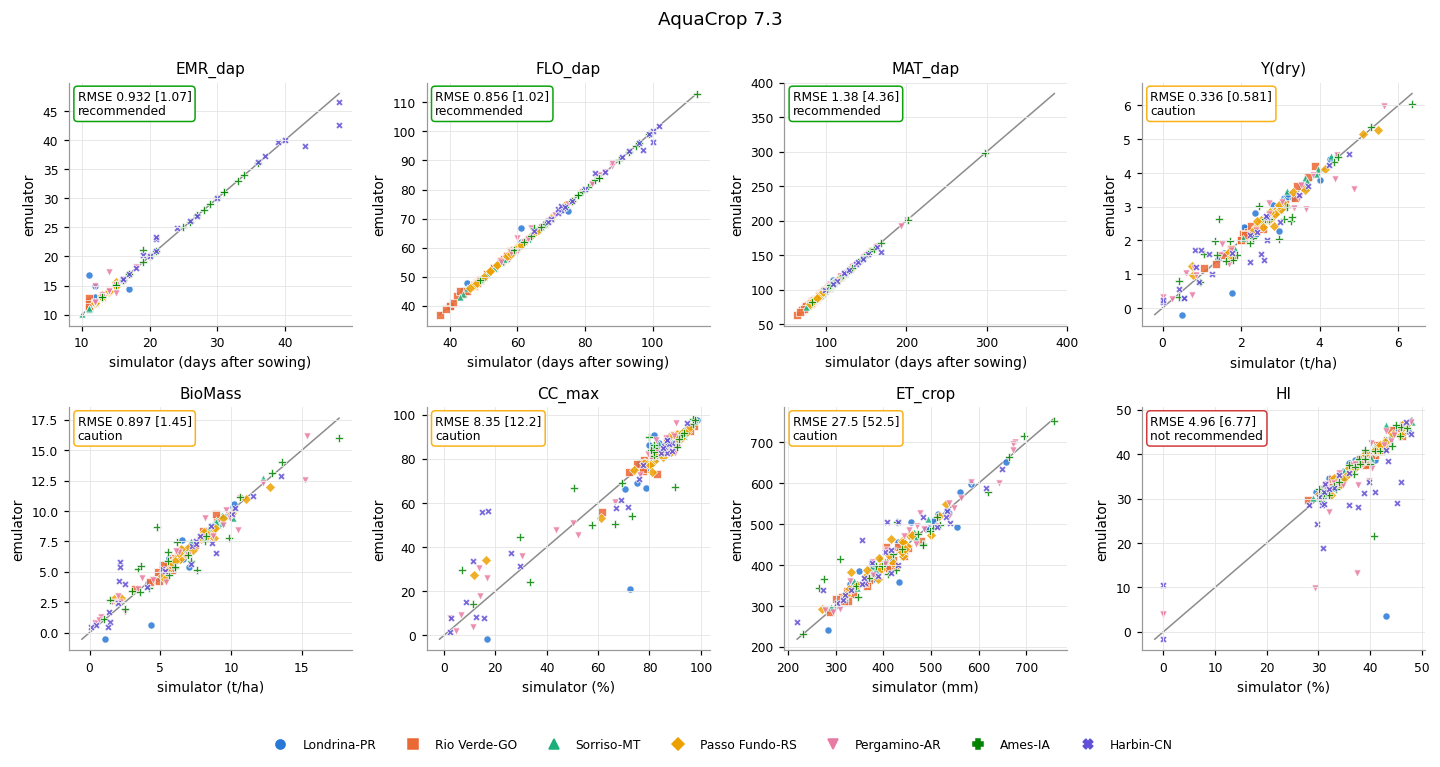

In [10]:
PANELS = {"dssat": ["EDAT_dap", "ADAT_dap", "MDAT_dap", "HWAM", "CWAM", "LAIX", "ETCM", "HIAM"],
          "aquacrop": ["EMR_dap", "FLO_dap", "MAT_dap", "Y(dry)", "BioMass", "CC_max", "ET_crop", "HI"]}

def scatter_grid(name):
    Y, P, info = truth[name][1], pred[name], truth[name][2]
    cols = [c for c in PANELS[name] if c in Y and c in P]
    nc = 4; nr = int(np.ceil(len(cols) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(3.3 * nc, 3.1 * nr + 0.5))
    acc = emus[name].card.get("acceptance", {})
    for ax, c in zip(axes.flat, cols):
        y, p = Y[c], P.loc[Y.index, c]
        for s in SITE_ORDER:
            i = info.index[info["point"] == s]
            ax.scatter(y.loc[i], p.loc[i], s=22, alpha=0.85, edgecolor="white", linewidth=0.5, **STYLE[s])
        lo, hi = np.nanmin([y.min(), p.min()]), np.nanmax([y.max(), p.max()])
        ax.plot([lo, hi], [lo, hi], color="0.55", lw=1, zorder=0)
        ok = y.notna() & p.notna()
        rmse = np.sqrt(((p[ok] - y[ok]) ** 2).mean())
        card = acc.get(c, {})
        ax.text(0.03, 0.97, f"RMSE {rmse:.3g} [{card.get('rmse', np.nan):.3g}]\n{card.get('level', '')}",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=LEVEL_COLOR.get(card.get("level"), "0.7")))
        u = UNITS.get(c, "days after sowing" if c.endswith("_dap") else "")
        ax.set(title=c, xlabel=f"simulator ({u})" if u else "simulator", ylabel="emulator")
    for ax in axes.flat[len(cols):]:
        ax.axis("off")
    fig.suptitle(LABEL[name], y=1.0); site_legend(fig); fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

scatter_grid("dssat")
scatter_grid("aquacrop")

### 5.3 Error at the new sites against the validation error

Ratio between the RMSE at the new sites and the out-of-fold RMSE of the card, for every output
(bar colour: acceptance level of the card). Ratios near 1 mean the card's error is a fair
description of what a user gets at a new site; with few seasons per site the ratio is noisy.

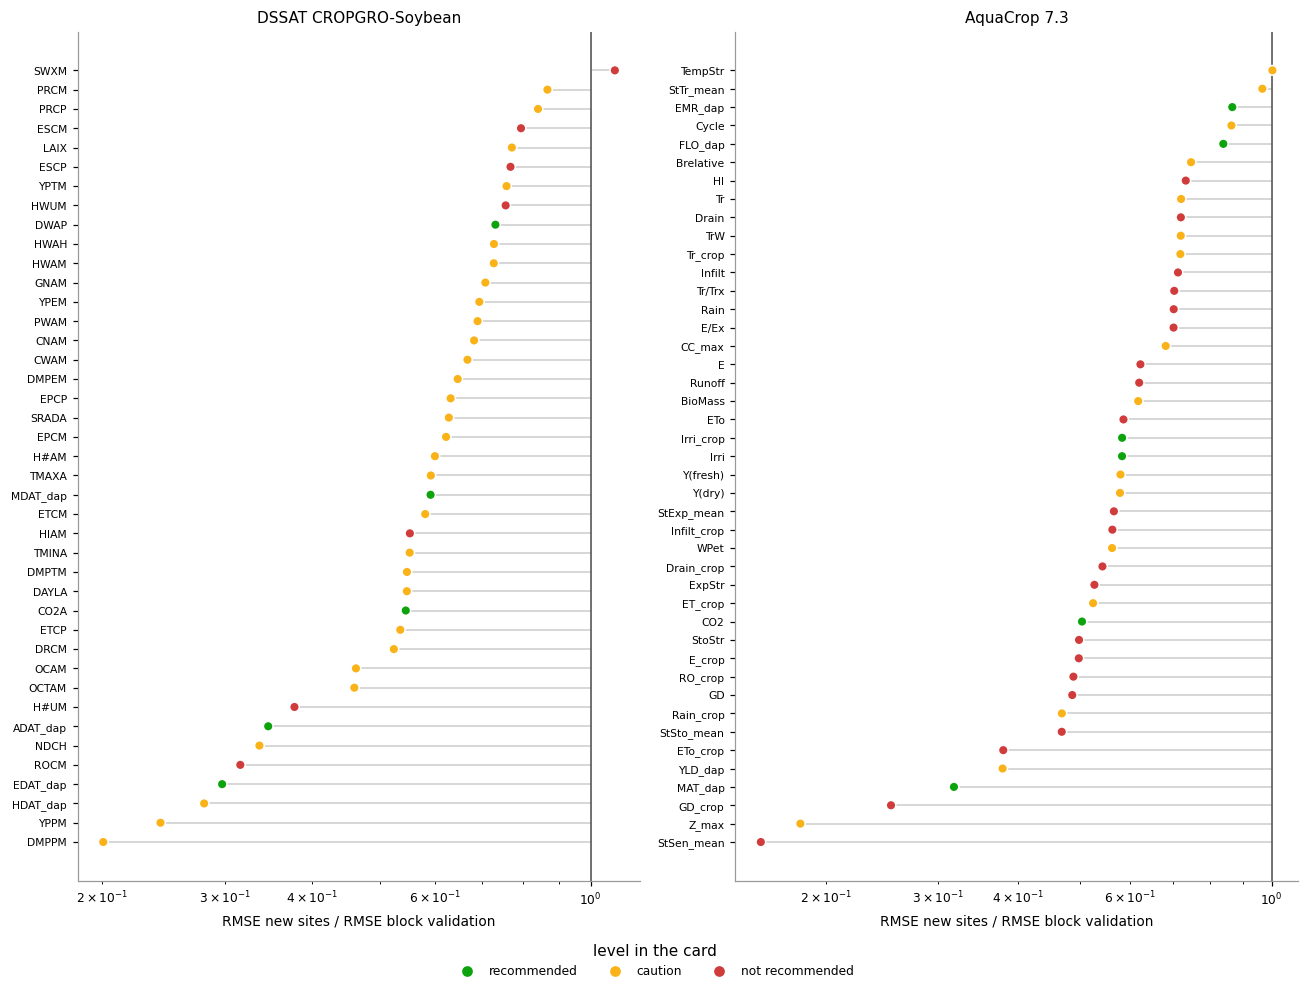

dssat: median ratio 0.60 over 41 outputs
aquacrop: median ratio 0.58 over 43 outputs


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 9))
for ax, name in zip(axes, emus):
    t = tables[name].dropna(subset=["card_rmse"])
    t = t.assign(ratio=t["rmse"] / t["card_rmse"]).sort_values("ratio")
    yy = np.arange(len(t))
    ax.hlines(yy, 1, t["ratio"], color="0.8", lw=1)
    ax.scatter(t["ratio"], yy, s=40, color=[LEVEL_COLOR.get(l, "0.7") for l in t["card_level"]],
               edgecolor="white", linewidth=1, zorder=3)
    ax.set_yticks(yy, t.index)
    ax.axvline(1, color="0.3", lw=1)
    ax.set(xscale="log", title=LABEL[name], xlabel="RMSE new sites / RMSE block validation")
    ax.tick_params(axis="y", labelsize=7); ax.grid(axis="y", visible=False)
h = [plt.Line2D([], [], ls="", marker="o", color=c) for c in LEVEL_COLOR.values()]
fig.legend(h, list(LEVEL_COLOR), loc="lower center", ncol=3, title="level in the card")
fig.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()
for name in emus:
    t = tables[name].dropna(subset=["card_rmse"])
    print(f"{name}: median ratio {np.median(t['rmse'] / t['card_rmse']):.2f} over {len(t)} outputs")

### 5.4 Yield, year by year

Filled markers: simulator; hollow markers: emulator; the vertical segment joins the two values of a
season. Every season has its own cultivar and sowing date.

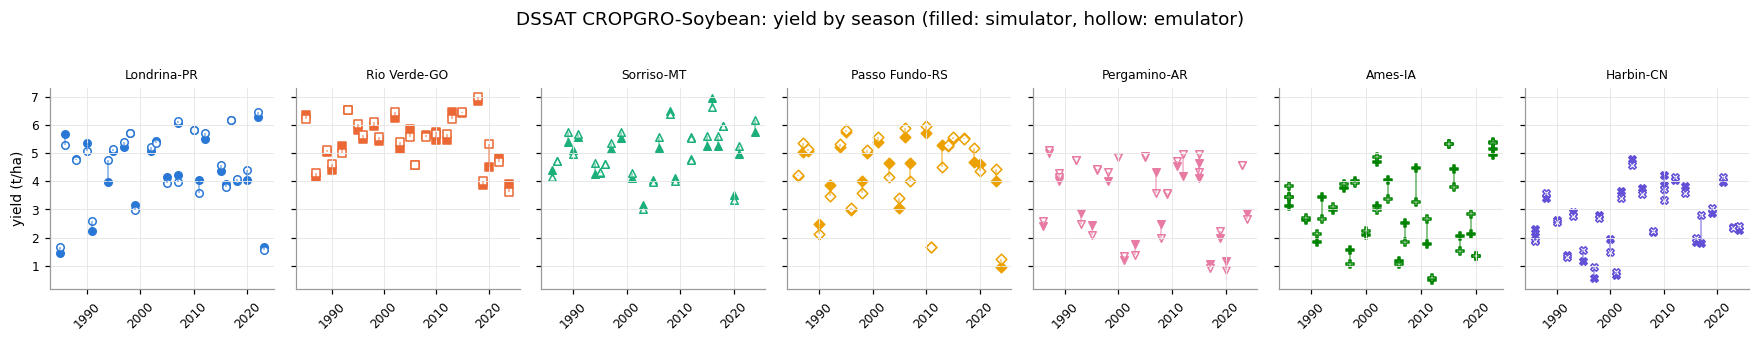

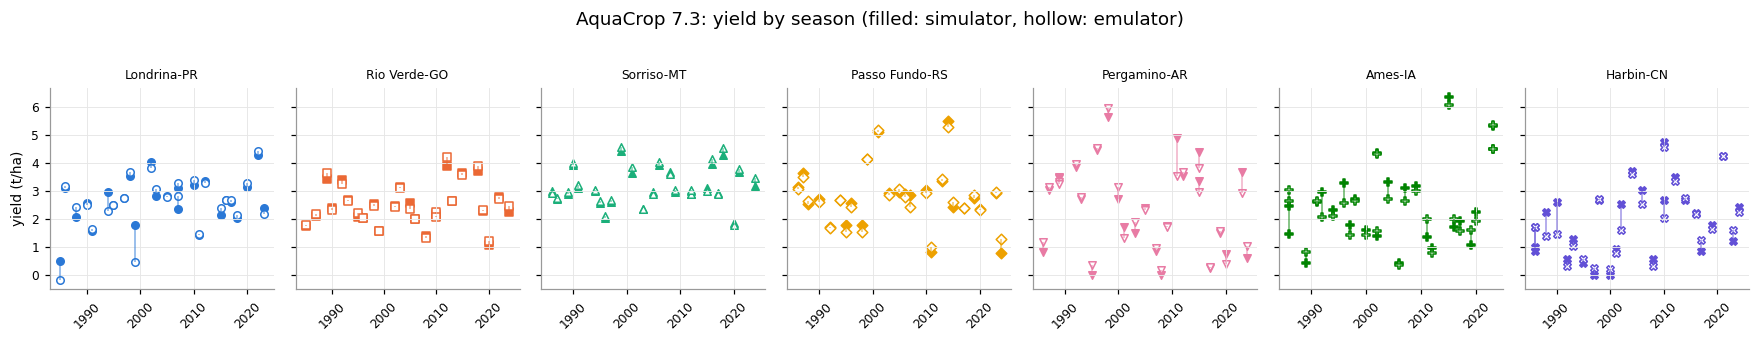

In [12]:
def by_year(name, col, scale=1.0):
    Y, P, info = truth[name][1], pred[name], truth[name][2]
    design = pd.read_parquet((dssat_dir if name == "dssat" else aq_dir) / "design.parquet").set_index("sample")
    d = pd.DataFrame({"site": info["point"], "sim": Y[col] * scale, "emu": P.loc[Y.index, col] * scale,
                      "year": design.loc[Y.index, "year"]}).dropna()
    fig, axes = plt.subplots(1, len(SITE_ORDER), figsize=(2.3 * len(SITE_ORDER), 3), sharey=True)
    for ax, s in zip(axes, SITE_ORDER):
        t = d[d["site"] == s].sort_values("year")
        st = STYLE[s]
        ax.vlines(t["year"], t["sim"], t["emu"], color=st["color"], lw=1, alpha=0.6)
        ax.scatter(t["year"], t["sim"], s=24, color=st["color"], marker=st["marker"])
        ax.scatter(t["year"], t["emu"], s=24, facecolor="white", edgecolor=st["color"], marker=st["marker"])
        ax.set_title(s, fontsize=8); ax.tick_params(axis="x", labelrotation=45)
    axes[0].set_ylabel("yield (t/ha)")
    fig.suptitle(f"{LABEL[name]}: yield by season (filled: simulator, hollow: emulator)", y=1.02)
    fig.tight_layout(); plt.show()

by_year("dssat", "HWAM", 1e-3)
by_year("aquacrop", "Y(dry)")

### 5.5 Where the errors are

Yield error against the rain of the crop period and against water regime (rainfed vs. no water
stress). Large errors in dry seasons point to the water balance as the hard part to emulate.

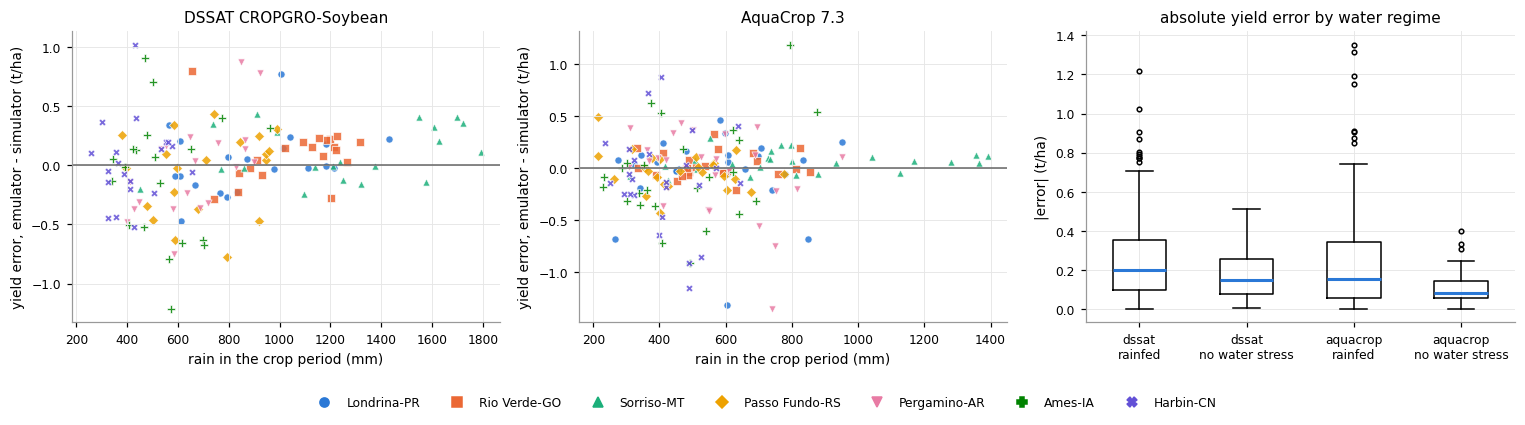

In [13]:
design_d = pd.read_parquet(dssat_dir / "design.parquet").set_index("sample")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, ycol, rcol, scale) in zip(axes[:2], (("dssat", "HWAM", "PRCM", 1e-3), ("aquacrop", "Y(dry)", "Rain_crop", 1.0))):
    Y, P, info = truth[name][1], pred[name], truth[name][2]
    err = (P.loc[Y.index, ycol] - Y[ycol]) * scale
    rain = Y[rcol] if rcol in Y else np.nan
    for s in SITE_ORDER:
        i = info.index[info["point"] == s]
        ax.scatter(rain.loc[i], err.loc[i], s=22, alpha=0.85, edgecolor="white", linewidth=0.5, **STYLE[s])
    ax.axhline(0, color="0.4", lw=1)
    ax.set(title=LABEL[name], xlabel="rain in the crop period (mm)", ylabel="yield error, emulator - simulator (t/ha)")
rows = []
for name, ycol, scale in (("dssat", "HWAM", 1e-3), ("aquacrop", "Y(dry)", 1.0)):
    Y, P = truth[name][1], pred[name]
    water = design_d.loc[Y.index, "water"]
    for w, lab in ((True, "rainfed"), (False, "no water stress")):
        e = ((P.loc[Y.index, ycol] - Y[ycol]) * scale)[water == w].dropna()
        rows.append((f"{name}\n{lab}", e.abs().to_numpy()))
ax = axes[2]
ax.boxplot([r[1] for r in rows], tick_labels=[r[0] for r in rows], widths=0.5,
           medianprops=dict(color="#2a78d6", lw=2), flierprops=dict(markersize=3))
ax.set(title="absolute yield error by water regime", ylabel="|error| (t/ha)"); ax.tick_params(axis="x", labelsize=8)
site_legend(fig); fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

### 5.6 Do the emulators keep the difference between the two models?

Same seasons, two crop models. Left: yields of DSSAT against AquaCrop (simulators and emulators).
Right: the DSSAT − AquaCrop difference given by the emulators against the one given by the simulators.

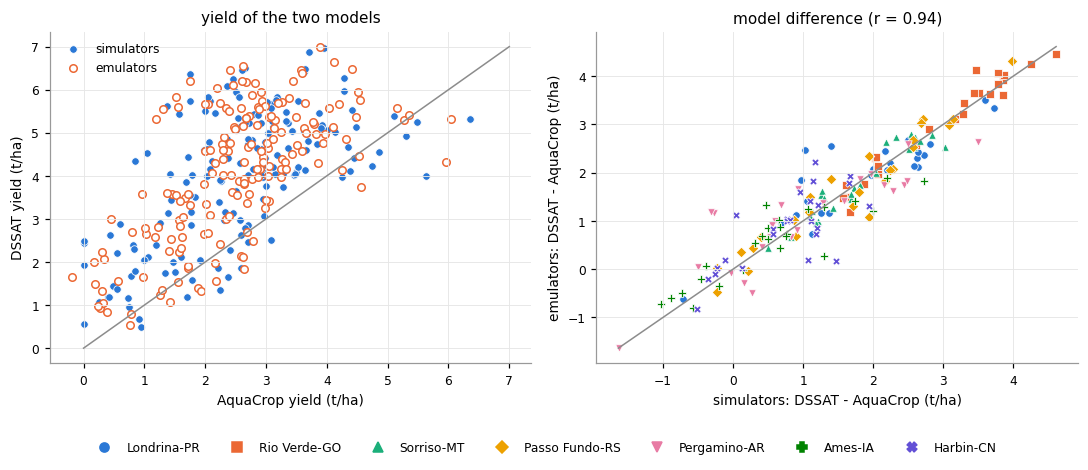

In [14]:
yd = pd.DataFrame({"sim_d": truth["dssat"][1]["HWAM"] / 1000, "emu_d": pred["dssat"]["HWAM"] / 1000})
ya = pd.DataFrame({"sim_a": truth["aquacrop"][1]["Y(dry)"], "emu_a": pred["aquacrop"]["Y(dry)"]})
both = yd.join(ya, how="inner").dropna().join(truth["dssat"][2]["point"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ax = axes[0]
ax.scatter(both["sim_a"], both["sim_d"], s=24, color="#2a78d6", label="simulators", edgecolor="white", linewidth=0.5)
ax.scatter(both["emu_a"], both["emu_d"], s=24, facecolor="white", edgecolor="#eb6834", label="emulators")
m = np.nanmax(both[["sim_a", "sim_d", "emu_a", "emu_d"]].to_numpy())
ax.plot([0, m], [0, m], color="0.55", lw=1); ax.legend()
ax.set(xlabel="AquaCrop yield (t/ha)", ylabel="DSSAT yield (t/ha)", title="yield of the two models")
ax = axes[1]
ds, de = both["sim_d"] - both["sim_a"], both["emu_d"] - both["emu_a"]
for s in SITE_ORDER:
    i = both.index[both["point"] == s]
    ax.scatter(ds.loc[i], de.loc[i], s=24, edgecolor="white", linewidth=0.5, **STYLE[s])
lo, hi = min(ds.min(), de.min()), max(ds.max(), de.max())
ax.plot([lo, hi], [lo, hi], color="0.55", lw=1)
ax.set(xlabel="simulators: DSSAT - AquaCrop (t/ha)", ylabel="emulators: DSSAT - AquaCrop (t/ha)",
       title=f"model difference (r = {ds.corr(de):.2f})")
site_legend(fig); fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

## 6. Application: sowing window

What emulators are for: thousands of seasons in seconds. For each site, the cultivar of its first
simulated season is sown every 5 days from 45 days before to 45 days after the GGCMI date, in
every year from 1990 to 2024 (rainfed). Line: median yield over the years; band: 25-75 %
percentiles. Dots: the simulated seasons of the site (other cultivars and years), for reference.

In [15]:
YEARS = range(1990, 2025)
OFFSETS = range(-45, 46, 5)
des = {"dssat": pd.read_parquet(dssat_dir / "design.parquet"), "aquacrop": pd.read_parquet(aq_dir / "design.parquet")}
pts = pd.read_parquet(dssat_dir / "points.parquet").set_index("id")
sweep = []
t0 = time.time()
for s in SITE_ORDER:
    if s not in pts.index:
        continue
    p = pts.loc[s]
    weather = fill_gaps(fetch(p["lat"], p["lon"], pipeline.WEATHER_START, pipeline.WEATHER_END))
    soil = soilgrids.fetch(p["lat"], p["lon"])
    first = des["dssat"][des["dssat"]["point"] == s].iloc[0]
    doy = int(first["planting_doy"])
    dates = [pd.Timestamp(y, 1, 1) + pd.Timedelta(days=doy - 1 + o) for y in YEARS for o in OFFSETS]
    for name, emu in emus.items():
        row = des[name].set_index("sample").loc[first["sample"]]
        res = emu.predict(weather, lat=p["lat"], elev=p["elev"], soil=soil, sowing=dates,
                          cultivar={k: row[k] for k in emu.cultivar_})
        col, scale = ("HWAM", 1e-3) if name == "dssat" else ("Y(dry)", 1.0)
        sweep.append(pd.DataFrame({"site": s, "model": name, "offset": [o for _ in YEARS for o in OFFSETS],
                                   "year": [y for y in YEARS for _ in OFFSETS],
                                   "yield": res.outputs[col].to_numpy() * scale,
                                   "rare": res.rare_inputs.str.len().to_numpy()}))
sweep = pd.concat(sweep, ignore_index=True)
print(f"{len(sweep)} emulated seasons in {time.time() - t0:.0f} s")

9310 emulated seasons in 7 s


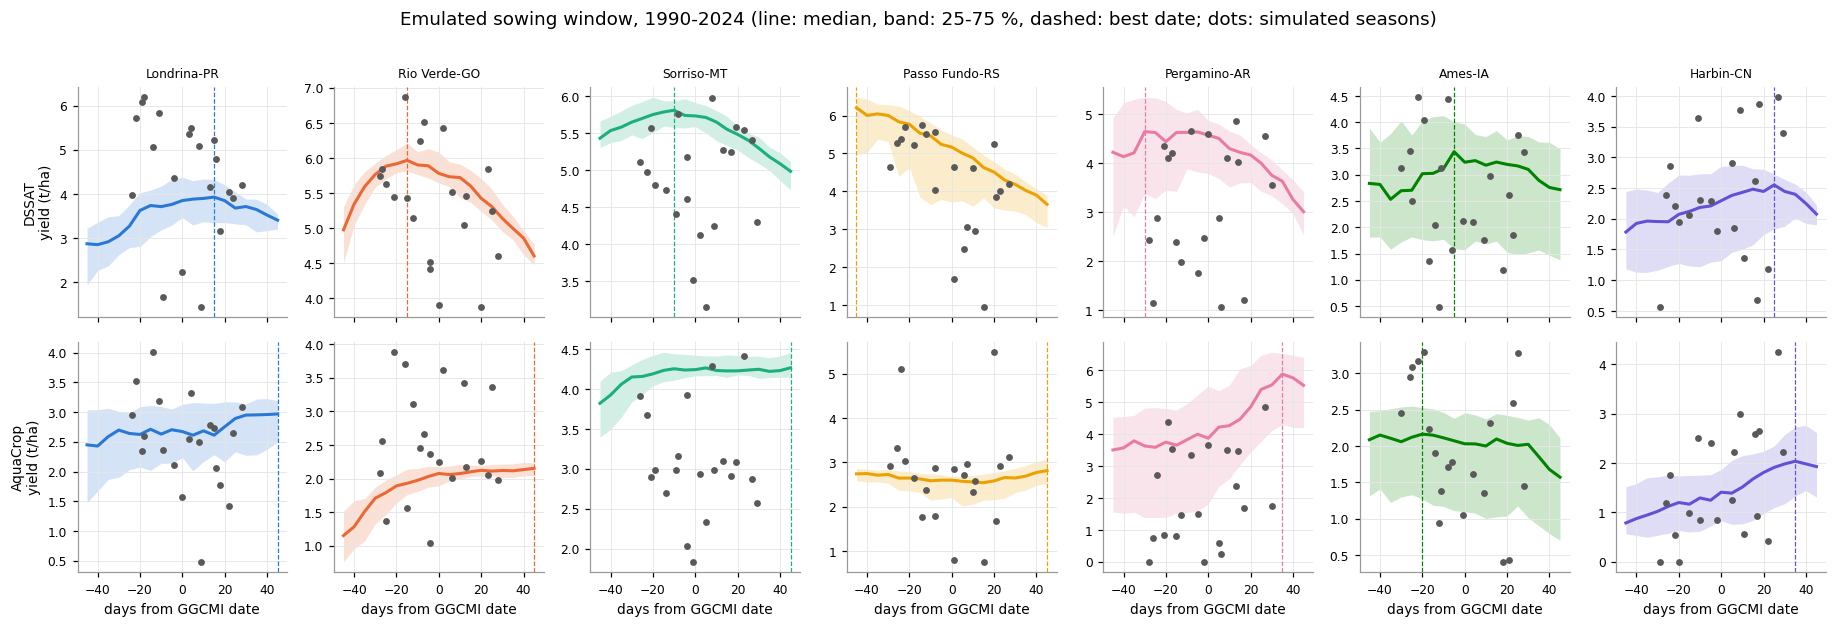

In [16]:
fig, axes = plt.subplots(2, len(SITE_ORDER), figsize=(2.4 * len(SITE_ORDER), 5.6), sharex=True)
for j, s in enumerate(SITE_ORDER):
    for i, (name, col, scale) in enumerate((("dssat", "HWAM", 1e-3), ("aquacrop", "Y(dry)", 1.0))):
        ax = axes[i, j]
        t = sweep[(sweep["site"] == s) & (sweep["model"] == name)]
        if t.empty:
            ax.axis("off"); continue
        q = t.groupby("offset")["yield"].quantile([0.25, 0.5, 0.75]).unstack()
        c = STYLE[s]["color"]
        ax.fill_between(q.index, q[0.25], q[0.75], color=c, alpha=0.2, lw=0)
        ax.plot(q.index, q[0.5], color=c, lw=2)
        best = q[0.5].idxmax()
        ax.axvline(best, color=c, lw=0.8, ls="--")
        d = des["dssat"].set_index("sample")
        Y, info = truth[name][1], truth[name][2]
        idx = info.index[(info["point"] == s) & d.loc[info.index, "water"].to_numpy()]
        ax.scatter(d.loc[idx, "sowing_offset"], Y.loc[idx, col] * scale, s=12, color="0.35", zorder=3)
        if i == 0:
            ax.set_title(s, fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{LABEL[name].split()[0]}\nyield (t/ha)")
        if i == 1:
            ax.set_xlabel("days from GGCMI date")
fig.suptitle("Emulated sowing window, 1990-2024 (line: median, band: 25-75 %, dashed: best date; dots: simulated seasons)", y=1.01)
fig.tight_layout(); plt.show()

Inputs outside the 0.5-99.5 % range of the training data (``rare_inputs``) in the sweep, by site:
these seasons deserve less trust.

In [17]:
display(sweep.assign(rare=sweep["rare"] > 0).pivot_table(index="site", columns="model", values="rare", aggfunc="mean")
        .reindex(SITE_ORDER).mul(100).round(1).rename_axis(columns="% seasons with rare inputs"))

% seasons with rare inputs,aquacrop,dssat
site,,
Londrina-PR,100.0,100.0
Rio Verde-GO,29.6,11.1
Sorriso-MT,11.1,11.1
Passo Fundo-RS,6.2,6.2
Pergamino-AR,100.0,100.0
Ames-IA,2.3,1.7
Harbin-CN,15.8,15.6


## 7. Run time

DSSAT: 38 ms/season | AquaCrop: 41 ms/season (4 processes; with file writing and, on a first run, the weather/soil downloads)
emulator (inputs ready): 11.6 µs/season


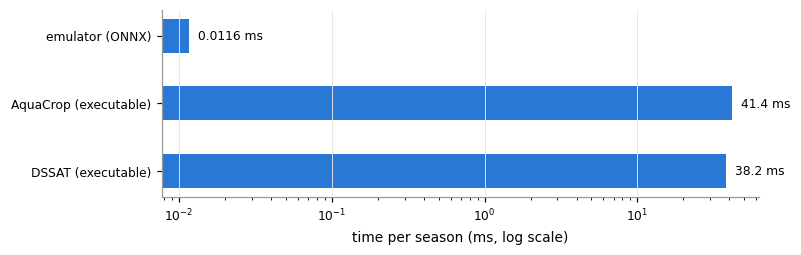

In [18]:
n = len(truth["dssat"][1])
X = used["dssat"][emus["dssat"].inputs_]
t0 = time.time(); emus["dssat"].predict_inputs(pd.concat([X] * 100)); t_emu = time.time() - t0
print(f"DSSAT: {1000 * t_dssat / n:.0f} ms/season | AquaCrop: {1000 * t_aq / n:.0f} ms/season "
      f"(4 processes; with file writing and, on a first run, the weather/soil downloads)")
print(f"emulator (inputs ready): {1e6 * t_emu / (100 * n):.1f} µs/season")
fig, ax = plt.subplots(figsize=(7, 2.2))
v = {"DSSAT (executable)": 1e3 * t_dssat / n, "AquaCrop (executable)": 1e3 * t_aq / n,
     "emulator (ONNX)": 1e3 * t_emu / (100 * n)}
ax.barh(list(v), list(v.values()), color="#2a78d6", height=0.5)
for k, x in v.items():
    ax.text(x * 1.15, k, f"{x:.3g} ms", va="center", fontsize=8)
ax.set(xscale="log", xlabel="time per season (ms, log scale)"); ax.grid(axis="y", visible=False)
plt.show()